In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

In [2]:
plt.figure(figsize=(8, 4))

<Figure size 800x400 with 0 Axes>

<Figure size 800x400 with 0 Axes>

In [3]:
df = pd.read_csv(r'E:\User_Retention\data\raw\orders.csv')

In [4]:
first_orders = df[df['order_number'] == 1][['user_id', 'order_dow']].copy()
first_orders['cohort'] = np.where(first_orders['order_dow'].isin([0, 6]), 'weekend', 'weekday')
df = df.merge(first_orders[['user_id', 'cohort']], on='user_id', how='left')

returning = df[df['order_number'] == 2][['user_id', 'cohort', 'days_since_prior_order']].copy()
returning['retention_bucket'] = pd.cut(
    returning['days_since_prior_order'],
    bins=[0, 7, 30, 60, 90, float('inf')],
    labels=['0-7d', '8-30d', '31-60d', '61-90d', '90d+']
)

retention_dist = returning.groupby(['cohort', 'retention_bucket'])['user_id'].count().reset_index()
matrix = retention_dist.pivot(index='cohort', columns='retention_bucket', values='user_id')
matrix_pct = matrix.div(matrix.sum(axis=1), axis=0) * 100

<Axes: xlabel='retention_bucket', ylabel='cohort'>

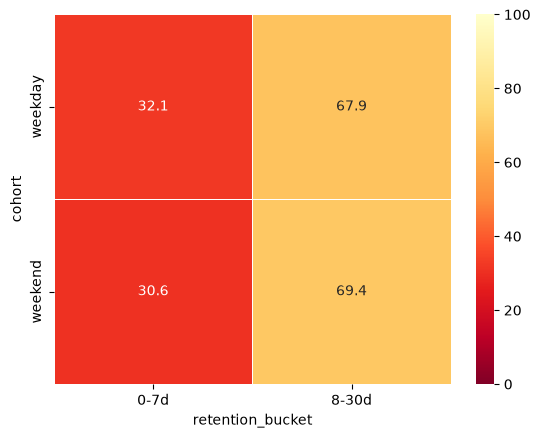

In [5]:
sns.heatmap(matrix_pct, annot=True, fmt='.1f', cmap='YlOrRd_r', linewidths=0.5, vmin=0, vmax=100)

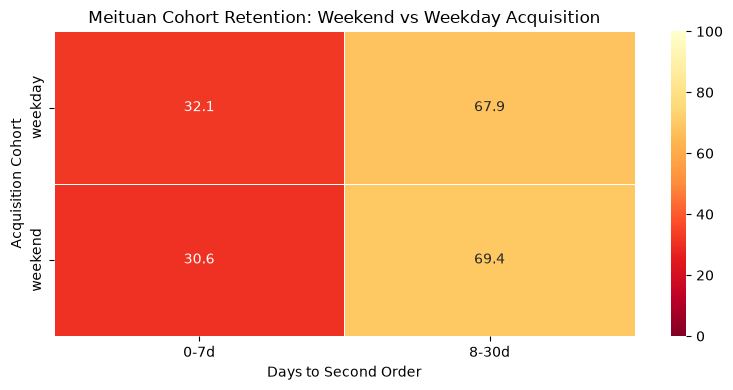

In [6]:
plt.figure(figsize=(8, 4))
sns.heatmap(matrix_pct, annot=True, fmt='.1f', cmap='YlOrRd_r', linewidths=0.5, vmin=0, vmax=100)
plt.title('Meituan Cohort Retention: Weekend vs Weekday Acquisition')
plt.xlabel('Days to Second Order')
plt.ylabel('Acquisition Cohort')
plt.tight_layout()
plt.savefig('../outputs/retention_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

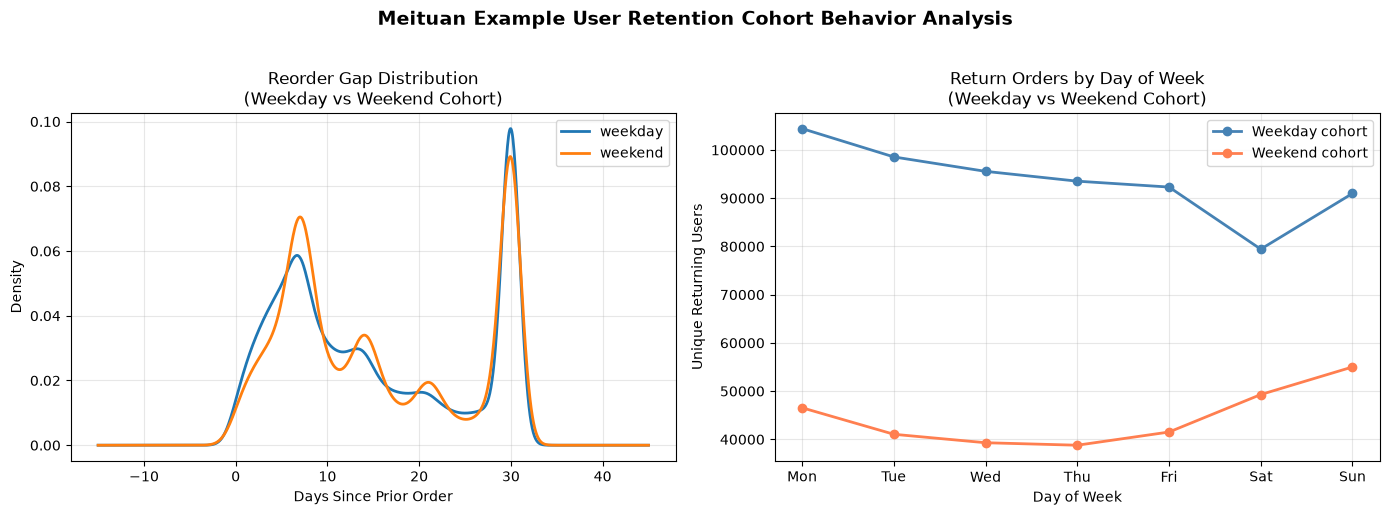

In [7]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))


for cohort, group in returning.groupby('cohort'):
    group['days_since_prior_order'].plot(
        kind='kde',
        ax=axes[0],
        label=cohort,
        linewidth=2
    )
axes[0].set_title('Reorder Gap Distribution\n(Weekday vs Weekend Cohort)')
axes[0].set_xlabel('Days Since Prior Order')
axes[0].set_ylabel('Density')
axes[0].legend()
axes[0].grid(alpha=0.3)


dow_map = {0:'Sun', 1:'Mon', 2:'Tue', 3:'Wed', 4:'Thu', 5:'Fri', 6:'Sat'}
weekly = df[df['order_number'] > 1].copy()
weekly['day_name'] = weekly['order_dow'].map(dow_map)

weekday_data = weekly[weekly['cohort'] == 'weekday'].groupby('day_name')['user_id'].nunique()
weekend_data = weekly[weekly['cohort'] == 'weekend'].groupby('day_name')['user_id'].nunique()

day_order = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
axes[1].plot(day_order, [weekday_data.get(d, 0) for d in day_order],
             marker='o', linewidth=2, label='Weekday cohort', color='steelblue')
axes[1].plot(day_order, [weekend_data.get(d, 0) for d in day_order],
             marker='o', linewidth=2, label='Weekend cohort', color='coral')
axes[1].set_title('Return Orders by Day of Week\n(Weekday vs Weekend Cohort)')
axes[1].set_xlabel('Day of Week')
axes[1].set_ylabel('Unique Returning Users')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('Meituan Example User Retention Cohort Behavior Analysis', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../outputs/retention_linegraph.png', dpi=150, bbox_inches='tight')
plt.show()